In [21]:
from dotenv import load_dotenv
load_dotenv()

True

In [22]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_ollama import OllamaEmbeddings
from langchain_community.vectorstores import InMemoryVectorStore
from langgraph.graph import START,END,StateGraph
from pydantic import BaseModel,Field
from typing import Literal,TypedDict,NotRequired,Annotated
from langchain_groq import ChatGroq


In [23]:
loader=PyPDFLoader("../Data/iot.pdf")

In [24]:
type(loader)


langchain_community.document_loaders.pdf.PyPDFLoader

In [25]:
pdf_doc=loader.load()


In [26]:
splitter=RecursiveCharacterTextSplitter(chunk_size=600,chunk_overlap=150)

In [27]:
splitted_doc=splitter.split_documents(pdf_doc)

In [28]:
embedding=OllamaEmbeddings(model="qwen3-embedding:8b")

In [29]:
vector_store=InMemoryVectorStore.from_documents(
    embedding=embedding,
    documents=splitted_doc
)

In [30]:
class RAG_STATE(TypedDict):
    question:str
    documents:NotRequired[list]
    context:NotRequired[str]
    answer:NotRequired[str]

In [31]:
#question->documents&context->answer
def get_context(state:RAG_STATE):
    doc=vector_store.similarity_search(query=state["question"])
    
    context=""
    for documents in doc:
        context=context+documents.page_content +"\n"
   
    return {"documents":doc,"context":context}

def get_answer(state:RAG_STATE):
    llm=ChatGroq(model="openai/gpt-oss-20b")
    Prompt=f""" You are a helpful assistant which answers user asked question according to the given context , dont use pretrained knowledge if you dont know the answer 
    respond i dont know
    question:{state["question"]}
    context:{state["context"]}
    """
    res=llm.invoke(Prompt)
   
    return {"answer":res.content}   

In [32]:
graph=StateGraph(RAG_STATE)

In [33]:
graph.add_node("context",get_context)
graph.add_node("answer",get_answer)
graph.add_edge(START,"context")
graph.add_edge("context","answer")
graph.add_edge("answer",END)

In [34]:
graph=graph.compile()

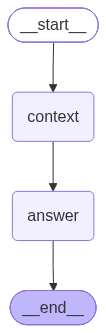

In [35]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [40]:
res=graph.invoke({"question":"what are the topics in the pdf"})

In [42]:
print(res["answer"])

**Topics in the PDF**

1. Communicating between devices using Bluetooth  
2. Finding out available Bluetooth devices  
3. Finding out available Wi‑Fi devices
